In [4]:
import h5py
data = h5py.File('iGluSnFR_Ras.mat')
a1 = data['iGluSnFR_Ras']['animal_1']
print(list(a1.keys()))
for key in a1.keys():
    item_a1 = a1[key]
    if not isinstance(item_a1,h5py.Group):
        print("key_name:",key,"shape:",item_a1.shape)
    else:
        print("subclasess:", list(item_a1.keys()))
    

['EMG', 'MUA', 'glutamate']
key_name: EMG shape: (2001, 865)
key_name: MUA shape: (2001, 865)
subclasess: ['Aud', 'BC', 'BCS2', 'FLS1', 'FLS2', 'HLS1', 'HLS2A', 'PtA', 'RSC', 'ULpS1', 'V1', 'V2L', 'V2MMLM', 'aM2', 'mFL']


In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
mua =a1['MUA'][:]
rsc =a1['glutamate']['RSC'][:]
print(f"shape:{rsc.shape}")

shape:(201, 865)


In [7]:
t_mua = np.linspace(-1,1, 2001)
t_rsc = np.linspace(-1,1,201)

In [8]:
mua_mean = np.mean(mua, axis=1)
mua_sem = np.std(mua, axis=1)/np.sqrt(865)
rsc_mean = np.mean(rsc,axis=1)
rsc_sem = rsc.std(axis=1)/np.sqrt(865)
print(mua_mean.shape, mua_sem.shape,rsc_mean.shape,rsc_sem.shape)

(2001,) (2001,) (201,) (201,)


Text(0.5, 0, 'Time from ripple center(s)')

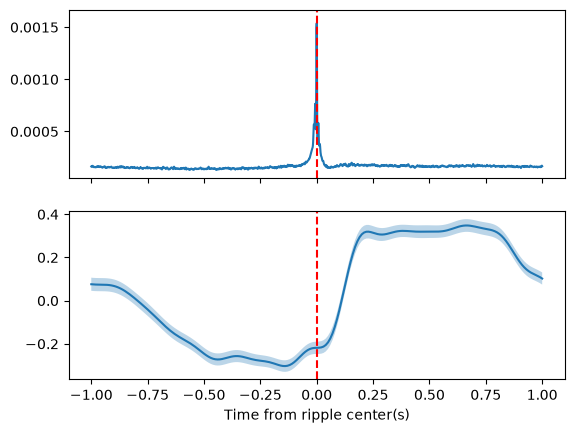

In [9]:
fig, axes = plt.subplots(2,1,sharex = True)
axes[0].plot(t_mua,mua_mean)
axes[0].fill_between(t_mua,mua_mean-mua_sem,mua_mean+mua_sem,alpha = 0.3)
axes[0].axvline(0,color='r',linestyle='--')
axes[1].plot(t_rsc,rsc_mean)
axes[1].fill_between(t_rsc,rsc_mean-rsc_sem,rsc_mean+rsc_sem,alpha = 0.3)
axes[1].axvline(0,color='r',linestyle='--')
axes[1].set_xlabel("Time from ripple center(s)")

(15, 201)


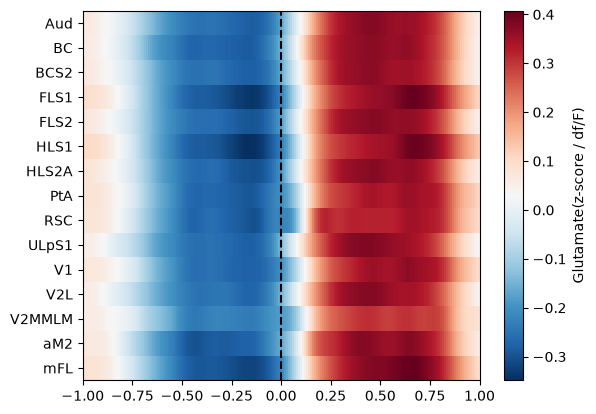

In [10]:
cortex_name = list(a1['glutamate'].keys())
cortex = a1['glutamate']
all_means = []
for key in cortex.keys():
    region_mean = cortex[key][:].mean(axis=1)
    all_means.append(region_mean)
matrix = np.array(all_means)
print(matrix.shape)
plt.imshow(matrix, aspect='auto',cmap='RdBu_r',extent=[-1,1,15,0],interpolation='nearest')
plt.yticks(np.arange(15)+0.5,cortex_name)
plt.colorbar(label="Glutamate(z-score / df/F)")
plt.axvline(0, color='k', linestyle='--')
plt.show()